Credit Card Fraud Detection and Transaction Risk Analytics

3. Exploratory Data Analysis
This notebook explores patterns in legitimate and fraudulent transactions to identify characteristics associated with fraud, understand temporal and behavioural patterns, assess financial impact, and identify variables that may be useful for subsequent predictive modelling.

The analysis is exploratory. Observed associations will not automatically be interpreted as causal relationships or standalone fraud rules.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
file_path = "../data/processed/credit_card_fraud_clean.csv"

df = pd.read_csv(
    file_path,
    parse_dates=['transaction_datetime', 'transaction_date']
)

df.shape

(100000, 47)

In [3]:
total_transactions = len(df)

fraud_transactions = df['is_fraud'].sum()

legitimate_transactions = total_transactions - fraud_transactions

fraud_rate = (
    fraud_transactions / total_transactions
) * 100

total_transaction_value = df['transaction_amount'].sum()

fraud_transaction_value = df.loc[
    df['is_fraud'] == 1,
    'transaction_amount'
].sum()

total_fraud_loss = df['fraud_amount_lost'].sum()

In [4]:
print(f"Total Transactions: {total_transactions:,}")
print(f"Legitimate Transactions: {legitimate_transactions:,}")
print(f"Fraudulent Transactions: {fraud_transactions:,}")
print(f"Fraud Rate: {fraud_rate:.2f}%")
print(f"Total Transaction Value: {total_transaction_value:,.2f}")
print(f"Fraud Transaction Value: {fraud_transaction_value:,.2f}")
print(f"Recorded Fraud Loss: {total_fraud_loss:,.2f}")

Total Transactions: 100,000
Legitimate Transactions: 97,945
Fraudulent Transactions: 2,055
Fraud Rate: 2.05%
Total Transaction Value: 12,687,197.67
Fraud Transaction Value: 349,209.64
Recorded Fraud Loss: 279,842.20


3.1 Fraud Overview and Financial Impact

Fraud Overview

The dataset contains 100,000 transactions with a total transaction value of approximately 12.69 million.

A total of 2,055 transactions are labelled as fraudulent, resulting in an observed fraud rate of approximately 2.05%.

Fraudulent transactions account for approximately 349,209.64 in transaction value, while the recorded fraud loss totals approximately 279,842.20.

Although fraudulent transactions represent a relatively small proportion of total transaction volume, their financial impact remains significant and warrants further analysis of when, where, and under what transaction characteristics fraud occurs.

In [5]:
monthly_fraud = (
    df.groupby('transaction_month')
      .agg(
          total_transactions=('transaction_id', 'count'),
          fraud_transactions=('is_fraud', 'sum'),
          fraud_loss=('fraud_amount_lost', 'sum')
      )
      .reset_index()
)

monthly_fraud['fraud_rate'] = (
    monthly_fraud['fraud_transactions']
    / monthly_fraud['total_transactions']
    * 100
)

monthly_fraud.round(2)

,transaction_month,total_transactions,fraud_transactions,fraud_loss,fraud_rate
0,1,8593,191,32358.42,2.22
1,2,7928,151,22091.11,1.90
2,3,8445,164,22120.54,1.94
3,4,8119,156,16177.54,1.92
4,5,8295,171,22662.32,2.06
5,6,8179,153,23026.80,1.87
6,7,8435,181,20512.69,2.15
7,8,8394,174,23184.77,2.07
8,9,8275,164,17379.78,1.98
9,10,8630,198,26000.04,2.29


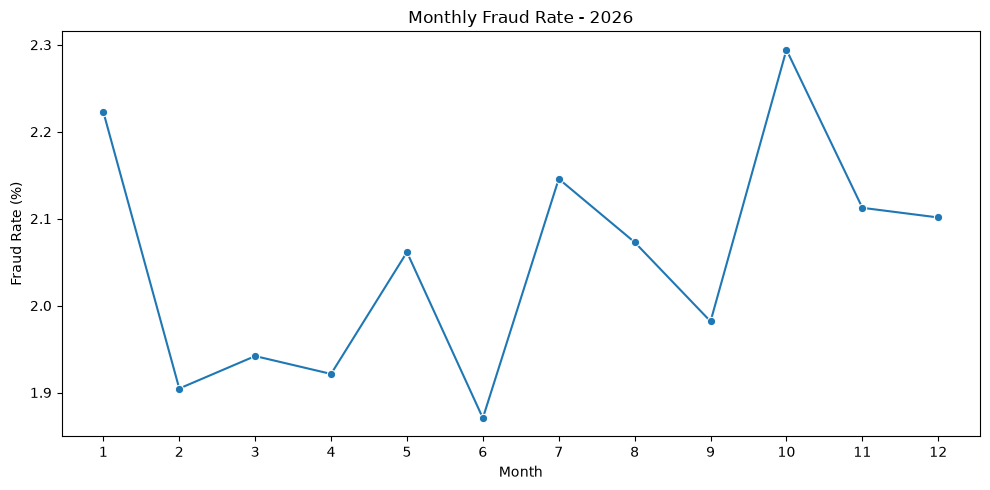

In [6]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=monthly_fraud,
    x='transaction_month',
    y='fraud_rate',
    marker='o'
)

plt.title('Monthly Fraud Rate - 2026')
plt.xlabel('Month')
plt.ylabel('Fraud Rate (%)')
plt.xticks(range(1, 13))
plt.tight_layout()

plt.show()

Monthly Fraud Pattern

The monthly fraud rate remains relatively close to 2% throughout 2026, although some month-to-month variation is present.

October 2026 records the highest observed monthly fraud rate at approximately 2.29%, with 198 fraudulent transactions from 8,630 total transactions.

June 2026 records the lowest observed monthly fraud rate at approximately 1.87%.

The month with the highest fraud rate is not the month with the greatest recorded financial loss. January records approximately 32,358.42 in fraud loss despite having a lower fraud rate than October.

This demonstrates that transaction volume, fraud frequency, fraud rate, and financial loss represent different dimensions of fraud risk and should be evaluated separately.

In [7]:
channel_analysis = (
    df.groupby('transaction_channel')
      .agg(
          total_transactions=('transaction_id', 'count'),
          fraud_transactions=('is_fraud', 'sum'),
          fraud_loss=('fraud_amount_lost', 'sum')
      )
      .reset_index()
)

channel_analysis['fraud_rate'] = (
    channel_analysis['fraud_transactions']
    / channel_analysis['total_transactions']
    * 100
)

channel_analysis.sort_values(
    'fraud_rate',
    ascending=False
).round(2)

,transaction_channel,total_transactions,fraud_transactions,fraud_loss,fraud_rate
3,Online,45532,1447,194047.26,3.18
2,Mobile App,12759,244,45769.73,1.91
0,ATM,5932,77,8039.32,1.30
1,In-store,35777,287,31985.89,0.80


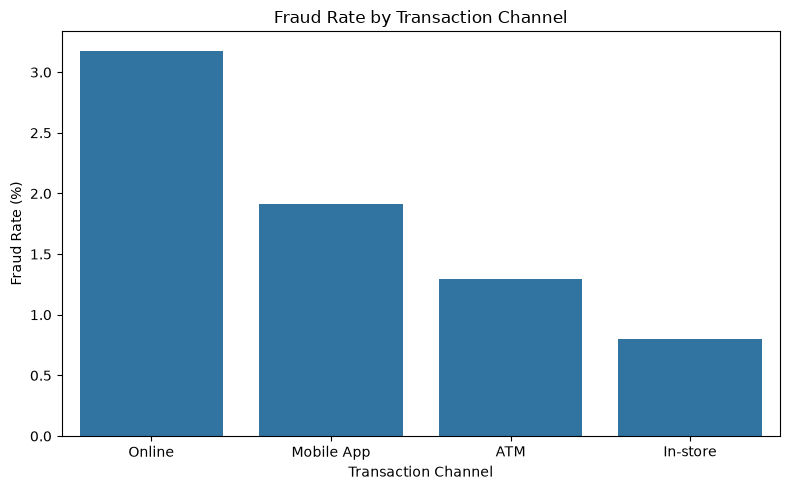

In [8]:
channel_plot = channel_analysis.sort_values(
    'fraud_rate',
    ascending=False
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=channel_plot,
    x='transaction_channel',
    y='fraud_rate'
)

plt.title('Fraud Rate by Transaction Channel')
plt.xlabel('Transaction Channel')
plt.ylabel('Fraud Rate (%)')
plt.tight_layout()

plt.show()

Fraud by Transaction Channel

Fraud activity varies considerably across transaction channels.

Online transactions have the highest observed fraud rate at approximately 3.18%, followed by Mobile App transactions at 1.91%, ATM transactions at 1.30%, and In-store transactions at 0.80%.

Online transactions account for 1,447 of the 2,055 observed fraud cases and approximately 194,047.26 of the total recorded fraud loss.

However, transaction channel should not be interpreted as a standalone fraud indicator. The majority of transactions within every channel, including Online transactions, remain legitimate.

The higher fraud rate associated with Online transactions warrants further investigation into related characteristics such as fraud type, card presence, authentication method, transaction amount, and geographic behaviour.

In [9]:
fraud_only = df[df['is_fraud'] == 1]

channel_fraud_type = pd.crosstab(
    fraud_only['transaction_channel'],
    fraud_only['fraud_type']
)

channel_fraud_type

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Synthetic-Identity
transaction_channel,,,,
ATM,29,18,12,18
In-store,61,36,142,48
Mobile App,90,61,29,64
Online,267,939,62,179


In [10]:
channel_fraud_type_pct = pd.crosstab(
    fraud_only['transaction_channel'],
    fraud_only['fraud_type'],
    normalize='index'
) * 100

channel_fraud_type_pct.round(2)

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Synthetic-Identity
transaction_channel,,,,
ATM,37.66,23.38,15.58,23.38
In-store,21.25,12.54,49.48,16.72
Mobile App,36.89,25.00,11.89,26.23
Online,18.45,64.89,4.28,12.37


Fraud Type by Transaction Channel

Fraud composition varies substantially across transaction channels.

Online fraud is predominantly Card-Not-Present, representing approximately 64.89% of fraudulent Online transactions. In contrast, Card-Present fraud accounts for approximately 49.48% of In-store fraud cases.

Mobile App and ATM fraud show more varied fraud-type distributions, with Account-Takeover representing the largest category in both channels.

These findings indicate that fraud patterns are not uniform across transaction channels. Transaction channel and fraud type should therefore be considered together when analysing fraud characteristics and designing monitoring strategies.

In [11]:
authentication_analysis = (
    df.groupby('is_fraud')[
        ['card_present', 'used_chip', 'used_pin']
    ]
    .mean()
    .mul(100)
    .round(2)
)

authentication_analysis

,card_present,used_chip,used_pin
is_fraud,,,
0,36.23,31.90,18.63
1,13.97,11.53,6.91


Authentication Behaviour

Authentication and physical-card indicators differ substantially between legitimate and fraudulent transactions.

Card-present activity occurs in approximately 36.23% of legitimate transactions compared with 13.97% of fraudulent transactions. Chip usage is observed in approximately 31.90% of legitimate transactions and 11.53% of fraudulent transactions, while PIN usage occurs in approximately 18.63% and 6.91%, respectively.

These differences suggest that authentication and card-presence variables may provide useful fraud-detection information.

However, these indicators are also related to transaction channel. For example, Online transactions naturally differ from In-store transactions in terms of card presence, chip usage, and PIN usage. Therefore, these variables should be interpreted jointly rather than as independent fraud rules.

In [12]:
hourly_analysis = (
    df.groupby('transaction_hour')
      .agg(
          total_transactions=('transaction_id', 'count'),
          fraud_transactions=('is_fraud', 'sum')
      )
      .reset_index()
)

hourly_analysis['fraud_rate'] = (
    hourly_analysis['fraud_transactions']
    / hourly_analysis['total_transactions']
    * 100
)

hourly_analysis.round(2)

,transaction_hour,total_transactions,fraud_transactions,fraud_rate
0,0,1012,27,2.67
1,1,597,50,8.38
2,2,361,27,7.48
3,3,230,26,11.30
4,4,256,20,7.81
5,5,516,9,1.74
6,6,1553,38,2.45
7,7,3159,65,2.06
8,8,4936,106,2.15
9,9,5381,90,1.67


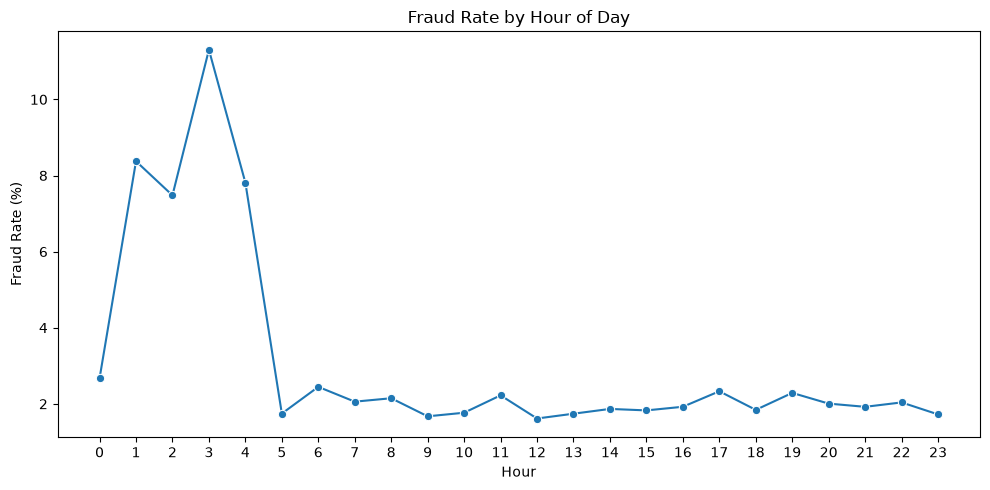

In [13]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=hourly_analysis,
    x='transaction_hour',
    y='fraud_rate',
    marker='o'
)

plt.title('Fraud Rate by Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Fraud Rate (%)')
plt.xticks(range(0, 24))
plt.tight_layout()

plt.show()

Fraud by Hour of Day

Fraud rates vary substantially by transaction hour.

The highest observed fraud rate occurs at 03:00, where approximately 11.30% of transactions are labelled as fraudulent. Elevated fraud rates are also observed at 01:00 (8.38%), 02:00 (7.48%), and 04:00 (7.81%).

From approximately 05:00 onward, hourly fraud rates generally remain closer to the overall dataset fraud rate.

However, the overnight periods also contain considerably lower transaction volumes. For example, only 230 transactions occur during the 03:00 hour, compared with several thousand transactions during most daytime and evening hours.

Therefore, the high overnight fraud rates should be interpreted alongside transaction volume rather than being treated as standalone evidence that transaction time determines fraud.

In [14]:
overnight_fraud = df[
    (df['is_fraud'] == 1) &
    (df['transaction_hour'].between(1, 4))
]

In [15]:
overnight_fraud['fraud_type'].value_counts()

fraud_type
Card-Not-Present      64
Account-Takeover      22
Card-Present          21
Synthetic-Identity    16
Name: count, dtype: int64

In [16]:
overnight_fraud['fraud_type'].value_counts()

fraud_type
Card-Not-Present      64
Account-Takeover      22
Card-Present          21
Synthetic-Identity    16
Name: count, dtype: int64

In [17]:
print("Fraud types (%)")
print(
    overnight_fraud['fraud_type']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTransaction channels (%)")
print(
    overnight_fraud['transaction_channel']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Fraud types (%)
fraud_type
Card-Not-Present      52.03
Account-Takeover      17.89
Card-Present          17.07
Synthetic-Identity    13.01
Name: proportion, dtype: float64

Transaction channels (%)
transaction_channel
Online        69.11
In-store      16.26
Mobile App    10.57
ATM            4.07
Name: proportion, dtype: float64


Overnight Fraud Profile

Further investigation of fraudulent transactions between 01:00 and 04:00 shows that approximately 69.11% occur through the Online transaction channel.

Card-Not-Present fraud represents approximately 52.03% of fraudulent transactions during this period, followed by Account-Takeover (17.89%), Card-Present (17.07%), and Synthetic-Identity (13.01%).

The overnight pattern is therefore strongly associated with Online and Card-Not-Present activity within this dataset.

However, this relationship does not establish that transaction hour or Online activity independently causes fraud. Transaction time, channel, fraud type, authentication behaviour, and other transaction characteristics may interact and should be assessed jointly.

In [18]:
geo_analysis = (
    df.groupby(
        ['international_transaction', 'high_risk_country']
    )
    .agg(
        total_transactions=('transaction_id', 'count'),
        fraud_transactions=('is_fraud', 'sum'),
        fraud_loss=('fraud_amount_lost', 'sum')
    )
    .reset_index()
)

geo_analysis['fraud_rate'] = (
    geo_analysis['fraud_transactions']
    / geo_analysis['total_transactions']
    * 100
)

geo_analysis.round(2)

,international_transaction,high_risk_country,total_transactions,fraud_transactions,fraud_loss,fraud_rate
0,0,0,44515,157,22350.53,0.35
1,1,0,50553,1353,181265.40,2.68
2,1,1,4932,545,76226.27,11.05


Geographic Risk Indicators

Fraud rates differ substantially when international transaction status and the high-risk-country indicator are considered together.

Domestic transactions that are not associated with the high-risk-country indicator have an observed fraud rate of approximately 0.35%.

International transactions not associated with the high-risk-country indicator have an observed fraud rate of approximately 2.68%.

Transactions that are both international and associated with the high-risk-country indicator have the highest observed fraud rate at approximately 11.05%.

No domestic transactions with a high-risk-country indicator are present in the dataset, indicating that the high-risk-country variable occurs only among international transactions in the available data.

The international/high-risk group shows the highest proportional fraud risk, while international transactions not associated with the high-risk-country indicator generate the greatest total recorded fraud loss because of their substantially larger transaction volume.

In [19]:
merchant_analysis = (
    df.groupby('merchant_category')
      .agg(
          total_transactions=('transaction_id', 'count'),
          fraud_transactions=('is_fraud', 'sum'),
          fraud_loss=('fraud_amount_lost', 'sum')
      )
      .reset_index()
)

merchant_analysis['fraud_rate'] = (
    merchant_analysis['fraud_transactions']
    / merchant_analysis['total_transactions']
    * 100
)

merchant_analysis.sort_values(
    'fraud_rate',
    ascending=False
).round(2)

,merchant_category,total_transactions,fraud_transactions,fraud_loss,fraud_rate
11,Online Retail,13417,446,45287.50,3.32
13,Travel & Airlines,6612,193,67964.06,2.92
4,Entertainment & Streaming,5848,146,3481.39,2.50
14,Utilities & Telecom,1036,24,1147.20,2.32
10,Hotel & Lodging,6360,133,42512.75,2.09
3,Electronics & Technology,6934,142,32218.03,2.05
9,Home Improvement,3824,74,11192.95,1.94
8,Healthcare & Pharmacy,7903,151,25798.68,1.91
5,Financial Services,873,16,7387.42,1.83
0,Auto & Transportation,3974,69,7179.49,1.74


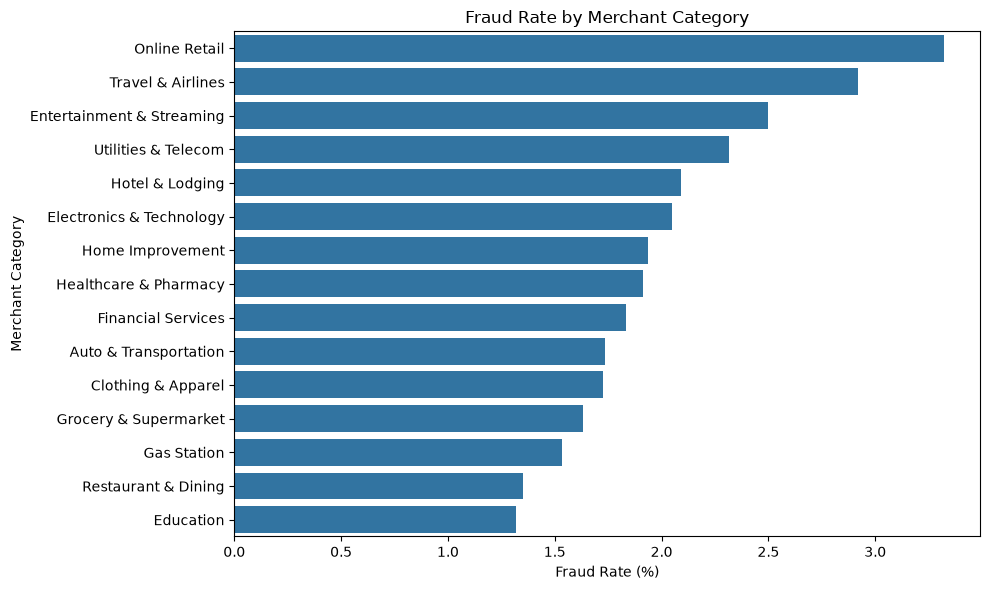

In [20]:
merchant_plot = merchant_analysis.sort_values(
    'fraud_rate',
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=merchant_plot,
    y='merchant_category',
    x='fraud_rate'
)

plt.title('Fraud Rate by Merchant Category')
plt.xlabel('Fraud Rate (%)')
plt.ylabel('Merchant Category')
plt.tight_layout()

plt.show()

Fraud by Merchant Category

Fraud rates vary across merchant categories.

Online Retail has the highest observed fraud rate at approximately 3.32%, with 446 fraudulent transactions from 13,417 total transactions.

Travel & Airlines has the second-highest observed fraud rate at approximately 2.92%. However, it records the greatest financial loss among the merchant categories, at approximately 67,964.06.

Entertainment & Streaming also shows an above-average fraud rate of approximately 2.50%.

At the lower end of the observed range, Restaurant & Dining and Education show fraud rates of approximately 1.35% and 1.32%, respectively.

These results demonstrate that fraud frequency, fraud rate, and financial impact do not necessarily identify the same merchant categories as highest risk.

In [21]:
behaviour_features = [
    'transaction_amount',
    'amount_vs_avg_ratio',
    'transactions_last_1h',
    'transactions_last_24h',
    'distance_from_home_km',
    'distance_from_last_tx_km',
    'num_declined_last_30d',
    'num_chargebacks_ever'
]

behaviour_summary = (
    df.groupby('is_fraud')[behaviour_features]
      .mean()
      .T
)

behaviour_summary.columns = [
    'Legitimate Mean',
    'Fraud Mean'
]

behaviour_summary['Difference %'] = (
    (
        behaviour_summary['Fraud Mean']
        - behaviour_summary['Legitimate Mean']
    )
    / behaviour_summary['Legitimate Mean']
    * 100
)

behaviour_summary.round(2)

,Legitimate Mean,Fraud Mean,Difference %
transaction_amount,125.97,169.93,34.90
amount_vs_avg_ratio,1.94,2.80,44.14
transactions_last_1h,0.77,1.38,79.50
transactions_last_24h,2.94,3.51,19.49
distance_from_home_km,4258.98,7070.11,66.00
distance_from_last_tx_km,927.85,1491.96,60.80
num_declined_last_30d,0.51,0.71,39.66
num_chargebacks_ever,0.36,0.64,76.46


Behavioural Characteristics Associated with Fraud

The behavioural comparison identifies several differences between legitimate and fraudulent transactions.

Fraudulent transactions have an average short-term transaction frequency approximately 79.50% higher than legitimate transactions during the previous one-hour period.

The mean number of previous chargebacks is approximately 76.46% higher among fraudulent transactions.

Fraudulent transactions also occur farther from the customer's home and previous transaction location on average, with differences of approximately 66.00% and 60.80%, respectively.

The amount relative to typical customer spending is approximately 44.14% higher among fraudulent transactions, while the average transaction amount is approximately 34.90% higher.

These differences identify potentially useful predictive signals but do not represent feature importance or standalone fraud rules. Distribution overlap, relationships between variables, and predictive performance require further assessment.

3.2 Exploratory Data Analysis Summary

The exploratory analysis identified several patterns associated with fraudulent transactions:

Fraud represents approximately 2.05% of all transactions, creating a substantially imbalanced classification problem.
Monthly fraud rates remain relatively stable around 2%, although October records the highest observed monthly fraud rate.
Fraud rate and financial loss do not necessarily peak during the same periods.
Online transactions have the highest fraud rate among transaction channels and account for the largest share of recorded fraud cases and losses.
Card-Not-Present fraud is the dominant fraud category among Online transactions.
Fraud rates are substantially elevated between 01:00 and 04:00, although transaction volumes are considerably lower during these hours.
Overnight fraud is predominantly associated with Online transactions and Card-Not-Present fraud.
International transactions have higher observed fraud rates than domestic transactions, particularly where the high-risk-country indicator is present.
Online Retail records the highest fraud rate among merchant categories, while Travel & Airlines records the greatest fraud loss.
Fraudulent transactions show higher short-term transaction velocity, geographic distance, previous chargebacks, spending deviation, recent declines, and transaction amounts on average.
Authentication indicators such as card presence, chip usage, and PIN usage occur less frequently among fraudulent transactions, although these measures are also related to transaction channel.
These findings provide candidate risk indicators for further SQL analysis and predictive modelling. Observed associations should not be interpreted as causal relationships or deterministic fraud rules.